# More Matplotlib

Matplotlib is the dominant plotting / visualization package in python. It is important to learn to use it well. In the last lecture, we saw some basic examples in the context of learning numpy. This week, we dive much deeper. The goal is to understand how matplotlib represents figures internally.

In [1]:
from matplotlib import pyplot as plt
%matplotlib inline 
# this tells Jupyter to display Matplotlib plots directly in the output of the notebook

## Figure and Axes

The *figure* is the highest level of organization of matplotlib objects. If we want, we can create a figure explicitly.

In [2]:
fig = plt.figure()

<Figure size 640x480 with 0 Axes>

In [3]:
fig = plt.figure(figsize=(13, 5))  
# set the width and height of the figure in inches, otherwise default is 6.4, 4.8

<Figure size 1300x500 with 0 Axes>

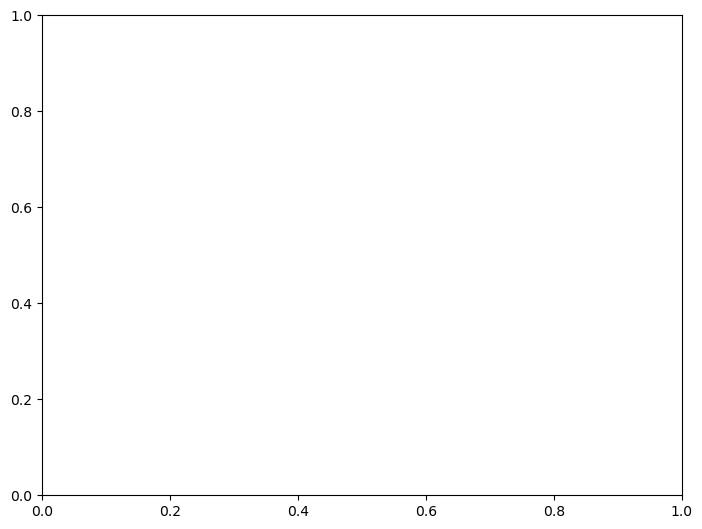

In [4]:
fig = plt.figure()
ax = fig.add_axes([0, 0, 1, 1])  
# [a,b,c,d] sets the dimension of the axes: (a,b) is the point in southwest corner of the rectangle, c represents width and d represents height

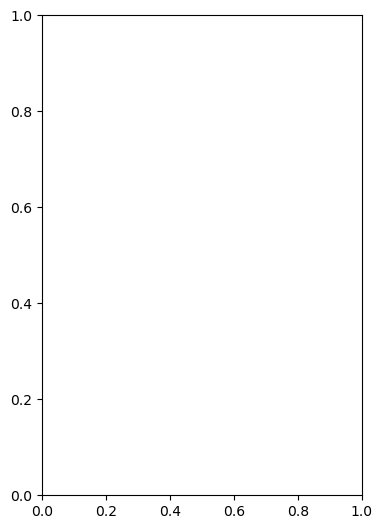

In [5]:
fig = plt.figure()
ax = fig.add_axes([0, 0, 0.5, 1])

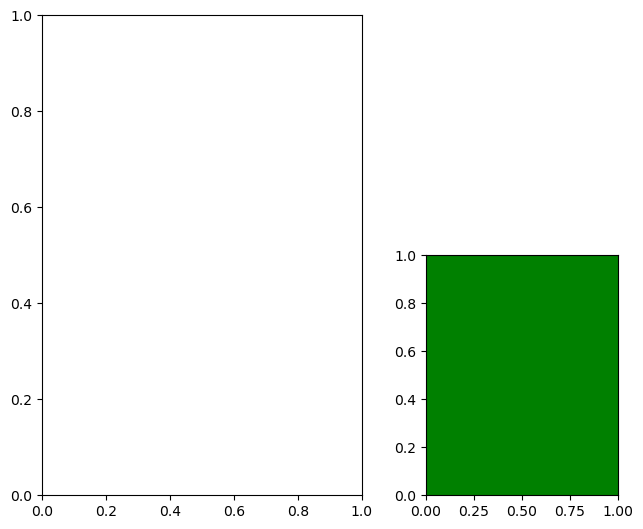

In [6]:
fig = plt.figure()
ax1 = fig.add_axes([0, 0, 0.5, 1])
ax2 = fig.add_axes([0.6, 0, 0.3, 0.5], facecolor='g')
# plt.savefig('test.png', bbox_inches='tight')

### Subplots

Subplot syntax is one way to specify the creation of multiple axes.

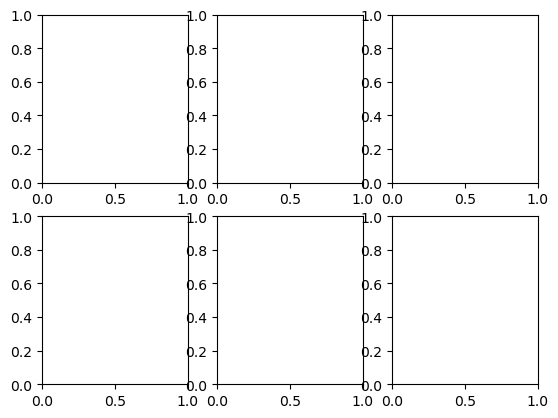

In [7]:
fig = plt.figure()
axes = fig.subplots(nrows=2, ncols=3)

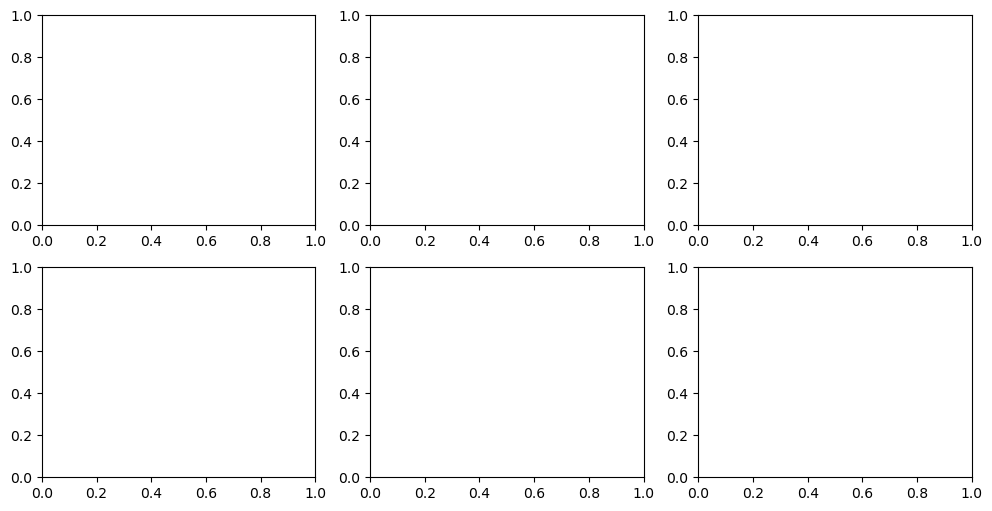

In [8]:
fig = plt.figure(figsize=(12, 6))
axes = fig.subplots(nrows=2, ncols=3)

In [9]:
axes

array([[<Axes: >, <Axes: >, <Axes: >],
       [<Axes: >, <Axes: >, <Axes: >]], dtype=object)

There is a shorthand for doing this all at once.

__This is our recommended way to create new figures!__

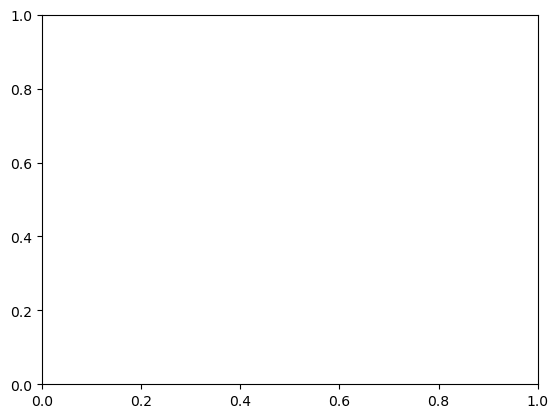

In [10]:
fig, ax = plt.subplots() # explicitly create Figure and Axes objects (Object-oriented style)

In [11]:
ax

<Axes: >

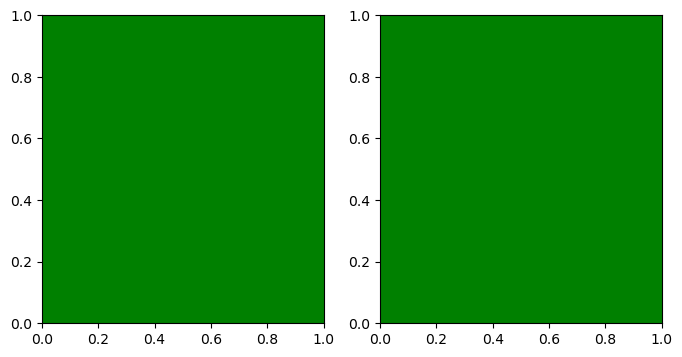

In [12]:
fig, axes = plt.subplots(ncols=2, figsize=(8, 4), subplot_kw={'facecolor': 'g'})

In [13]:
axes

array([<Axes: >, <Axes: >], dtype=object)

## Drawing into Axes

All plots are drawn into axes. It is easiest to understand how matplotlib works if you use the [object-oriented style](https://matplotlib.org/faq/usage_faq.html#coding-styles).

In [14]:
# create some data to plot
import numpy as np
x = np.linspace(-np.pi, np.pi, 100)
y = np.cos(x)
z = np.sin(6*x)

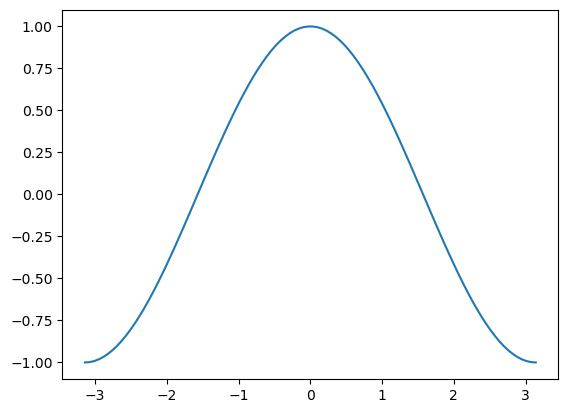

In [15]:
fig, ax = plt.subplots()
ax.plot(x, y)

This does the same thing as

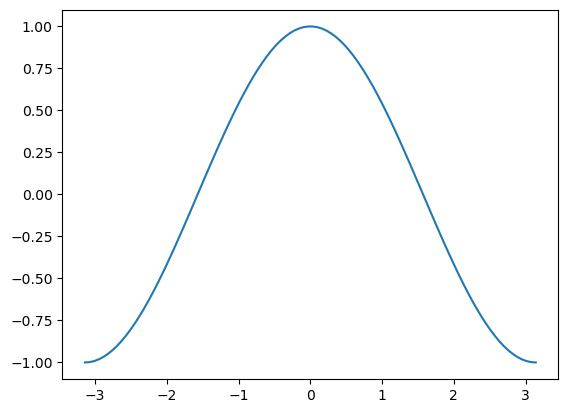

In [16]:
plt.plot(x, y)

This starts to matter when we have multiple axes to worry about.

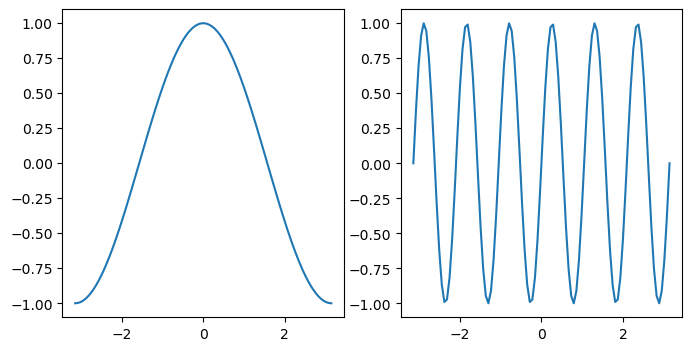

In [17]:
fig, axes = plt.subplots(figsize=(8, 4), ncols=2)
ax0, ax1 = axes
ax0.plot(x, y)
ax1.plot(x, z)

## Labeling Plots

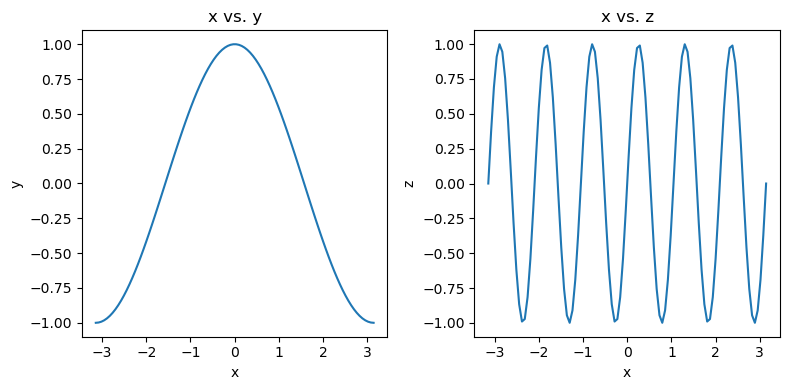

In [18]:
fig, axes = plt.subplots(figsize=(8, 4), ncols=2)
ax0, ax1 = axes

ax0.plot(x, y)
ax0.set_xlabel('x')
ax0.set_ylabel('y')
ax0.set_title('x vs. y')

ax1.plot(x, z)
ax1.set_xlabel('x')
ax1.set_ylabel('z')
ax1.set_title('x vs. z')

# squeeze everything in
plt.tight_layout()  #  adjust the padding between and around subplots

## Customizing Line Plots

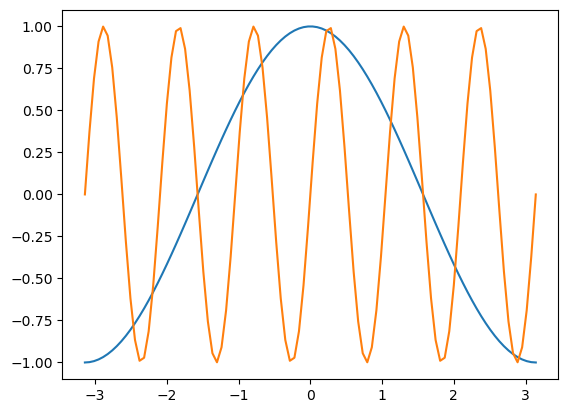

In [19]:
fig, ax = plt.subplots()
ax.plot(x, y, x, z)
# ax.plot(x, y, x, z); # a semicolon suppresses Jupyter's automatic display of the return value (text output)

It's simple to switch axes

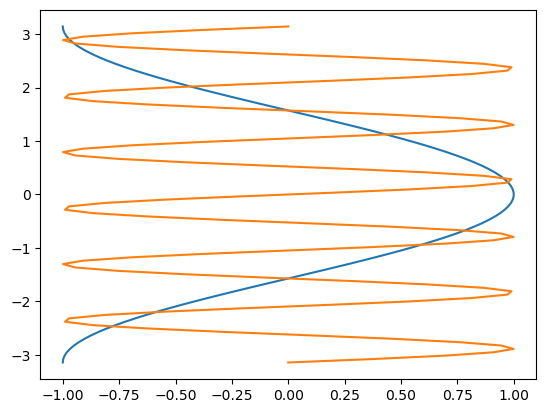

In [20]:
fig, ax = plt.subplots()
ax.plot(y, x, z, x)

A "parametric" graph:

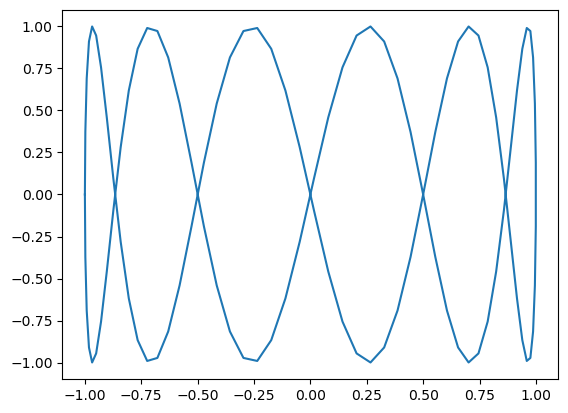

In [21]:
fig, ax = plt.subplots()
ax.plot(y, z)

### Line Styles

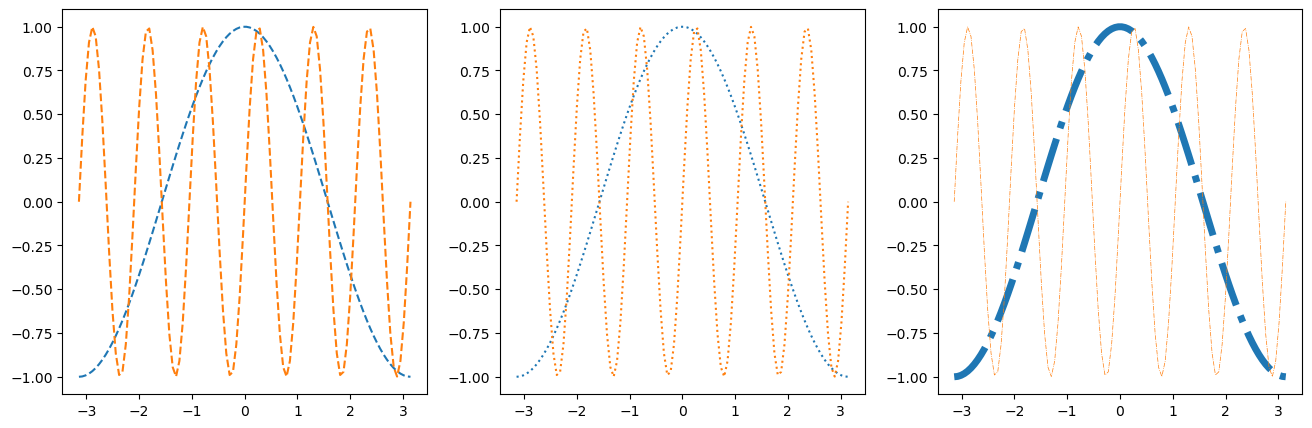

In [22]:
fig, axes = plt.subplots(figsize=(16, 5), ncols=3)
axes[0].plot(x, y, linestyle='dashed')
axes[0].plot(x, z, linestyle='--')

axes[1].plot(x, y, linestyle='dotted')
axes[1].plot(x, z, linestyle=':')

axes[2].plot(x, y, linestyle='dashdot', linewidth=5)
axes[2].plot(x, z, linestyle='-.', linewidth=0.5)


### Colors

As described in the [colors documentation](https://matplotlib.org/2.0.2/api/colors_api.html), there are some special codes for commonly used colors:

- b: blue
- g: green
- r: red
- c: cyan
- m: magenta
- y: yellow
- k: black
- w: white

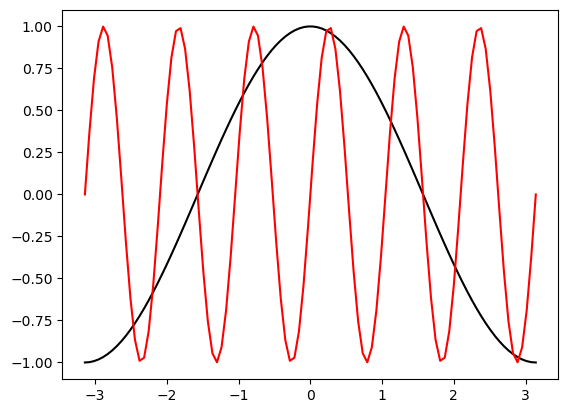

In [23]:
fig, ax = plt.subplots()
ax.plot(x, y, color='k')
ax.plot(x, z, color='r')

Other ways to specify colors:

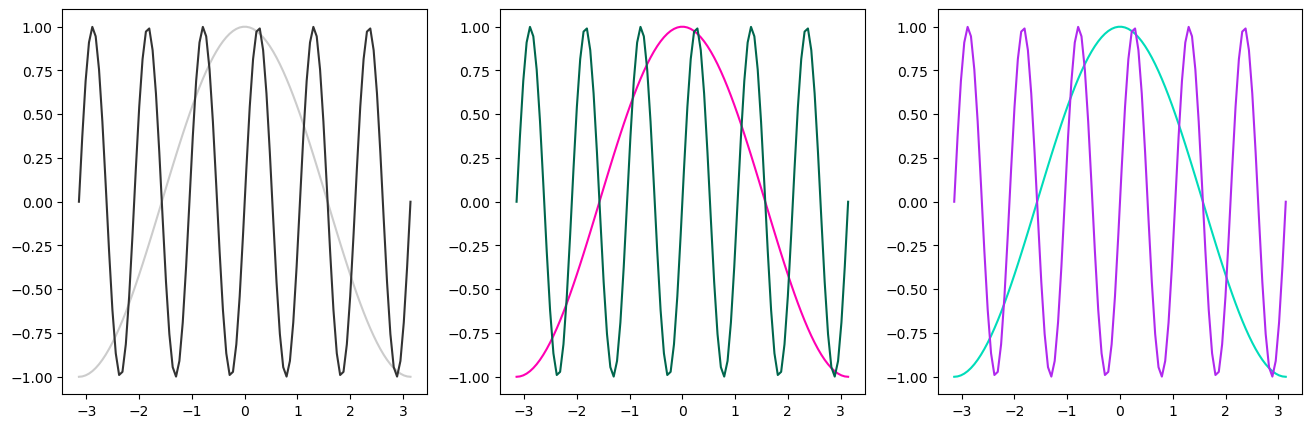

In [24]:
fig, axes = plt.subplots(figsize=(16, 5), ncols=3)

# grayscale
axes[0].plot(x, y, color='0.8')
axes[0].plot(x, z, color='0.2')

# RGB tuple
axes[1].plot(x, y, color=(1, 0, 0.7))
axes[1].plot(x, z, color=(0, 0.4, 0.3))

# HTML hex code
axes[2].plot(x, y, color='#00dcba')
axes[2].plot(x, z, color='#b029ee')

# an example of colors picker can be found here: https://www.w3schools.com/colors/colors_picker.asp

There is a default color cycle built into matplotlib.

In [25]:
plt.rcParams['axes.prop_cycle']

'#1f77b4'
'#ff7f0e'
'#2ca02c'
'#d62728'
'#9467bd'
'#8c564b'
'#e377c2'
'#7f7f7f'
'#bcbd22'
'#17becf'


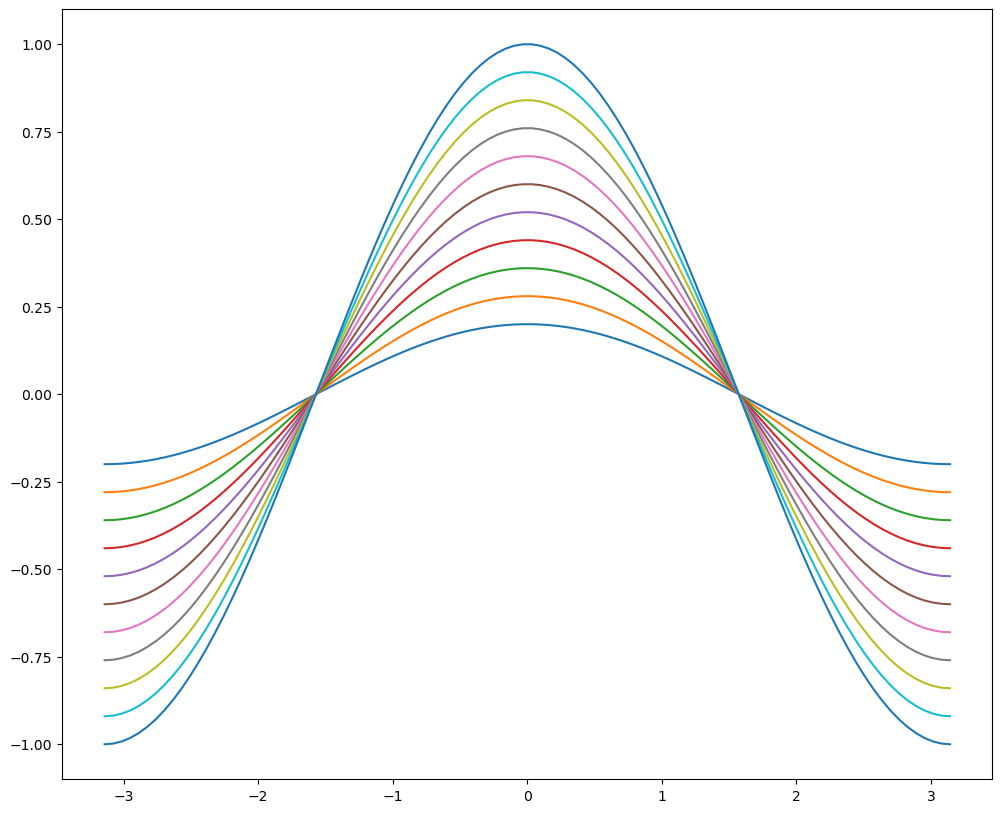

In [26]:
fig, ax = plt.subplots(figsize=(12, 10))
for factor in np.linspace(0.2, 1, 11):
    ax.plot(x, factor*y)  # using the default color cycle

### Markers

There are [lots of different markers](https://matplotlib.org/api/markers_api.html) availabile in matplotlib!

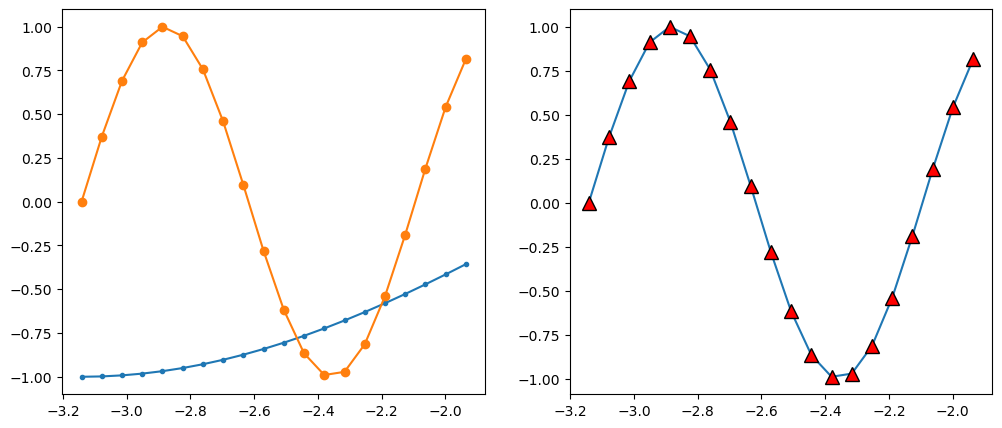

In [27]:
fig, axes = plt.subplots(figsize=(12, 5), ncols=2)

axes[0].plot(x[:20], y[:20], marker='.')
axes[0].plot(x[:20], z[:20], marker='o')

axes[1].plot(x[:20], z[:20], marker='^',
             markersize=10, markerfacecolor='r',
             markeredgecolor='k')


### Label, Ticks, and Gridlines

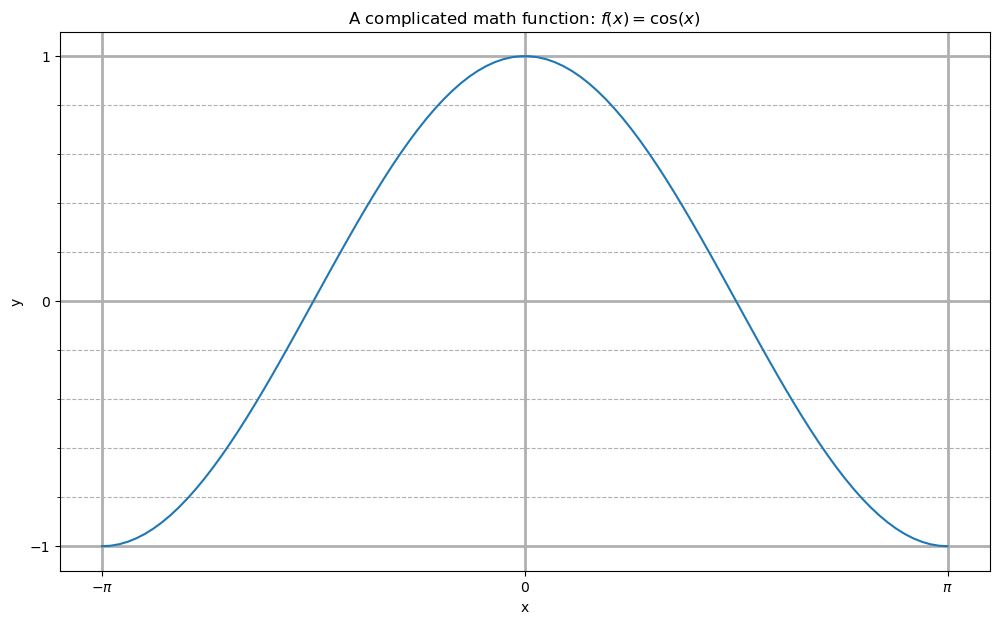

In [28]:
fig, ax = plt.subplots(figsize=(12, 7))
ax.plot(x, y)

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title(r'A complicated math function: $f(x) = \cos(x)$')
# prepend the letter r to strings that contain LaTeX, creating what can be called an ‘r-string’

ax.set_xticks(np.pi * np.array([-1, 0, 1]))
ax.set_xticklabels([r'$-\pi$', '0', r'$\pi$'])
ax.set_yticks([-1, 0, 1])

ax.set_yticks(np.arange(-1, 1.1, 0.2), minor=True)  # -1 to 1 with a step of 0.2
# ax.set_xticks(np.arange(-3, 3.1, 0.2), minor=True)

ax.grid(which='minor', linestyle='--')
ax.grid(which='major', linewidth=2)


### Axis Limits

(-3.0, 3.0)

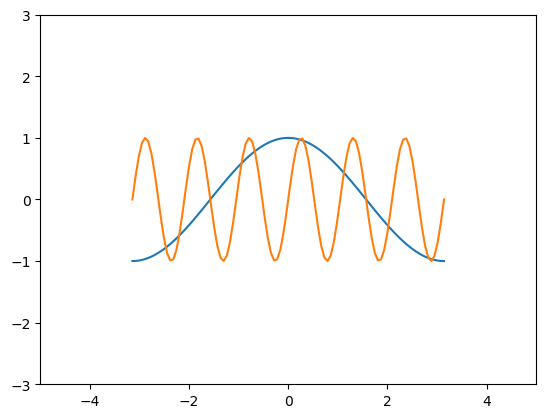

In [29]:
fig, ax = plt.subplots()
ax.plot(x, y, x, z)
ax.set_xlim(-5, 5)
ax.set_ylim(-3, 3)

### Text Annotations

Text(0, 0, 'the maximum')

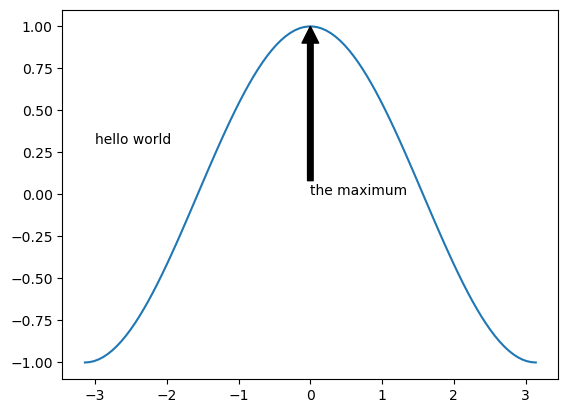

In [30]:
fig, ax = plt.subplots()
ax.plot(x, y)
ax.text(-3, 0.3, 'hello world')
ax.annotate('the maximum', xy=(0, 1),
             xytext=(0, 0), arrowprops={'facecolor': 'k'})
# text is displayed in position xytext. 
# an arrow pointing from the text to the annotated point xy is added by defining arrowprops

## Other 1D Plots

### Scatter Plots

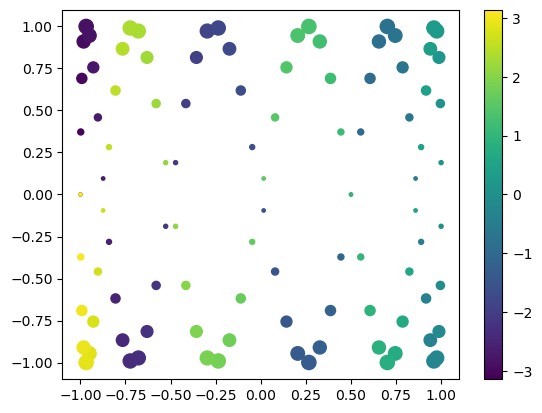

In [31]:
fig, ax = plt.subplots()

splot = ax.scatter(y, z, c=x, s=(100*z**2 + 5)) # s: marker size, c: marker colors
fig.colorbar(splot)

### Bar Plots

<BarContainer object of 3 artists>

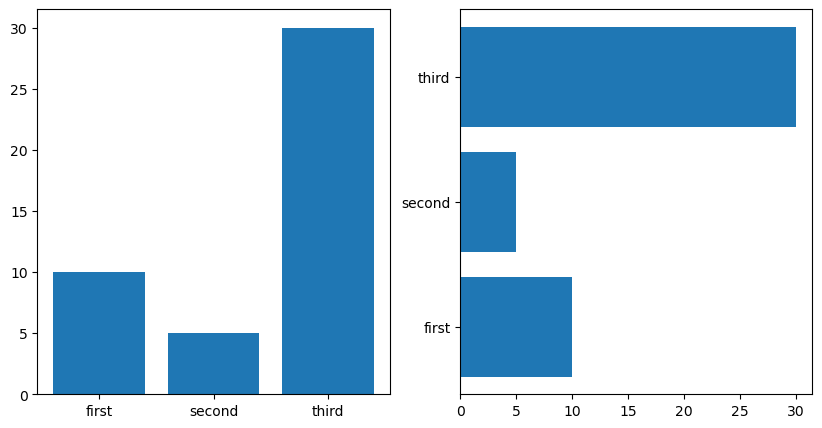

In [32]:
labels = ['first', 'second', 'third']
values = [10, 5, 30]

fig, axes = plt.subplots(figsize=(10, 5), ncols=2)
axes[0].bar(labels, values)
axes[1].barh(labels, values)

## 2D Plotting Methods

### imshow

In [33]:
x1d = np.linspace(-2*np.pi, 2*np.pi, 100)
y1d = np.linspace(-np.pi, np.pi, 50)
xx, yy = np.meshgrid(x1d, y1d)
f = np.cos(xx) * np.sin(yy)
print(f.shape)

(50, 100)


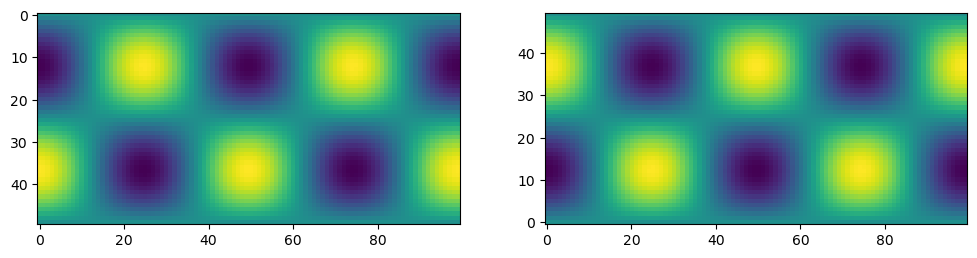

In [34]:
fig, ax = plt.subplots(figsize=(12,4), ncols=2)
ax[0].imshow(f)
ax[1].imshow(f, origin='lower')  
# the origin keyword argument controls how the image fills that bounding box
# for origin='upper', [0, 0] is at (left, top)
# for origin='lower', [0, 0] is at (left, bottom)

### pcolormesh

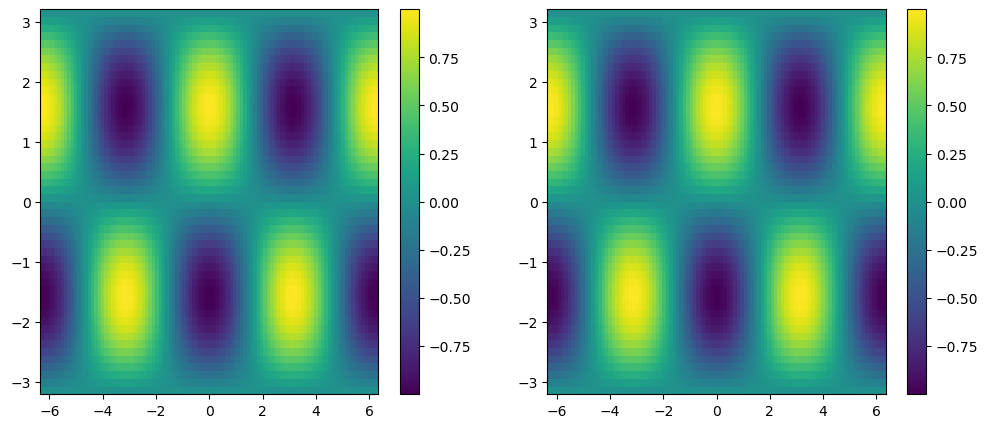

In [35]:
fig, ax = plt.subplots(ncols=2, figsize=(12, 5))
pc0 = ax[0].pcolormesh(x1d, y1d, f)
pc1 = ax[1].pcolormesh(xx, yy, f)
fig.colorbar(pc0, ax=ax[0])
fig.colorbar(pc1, ax=ax[1])


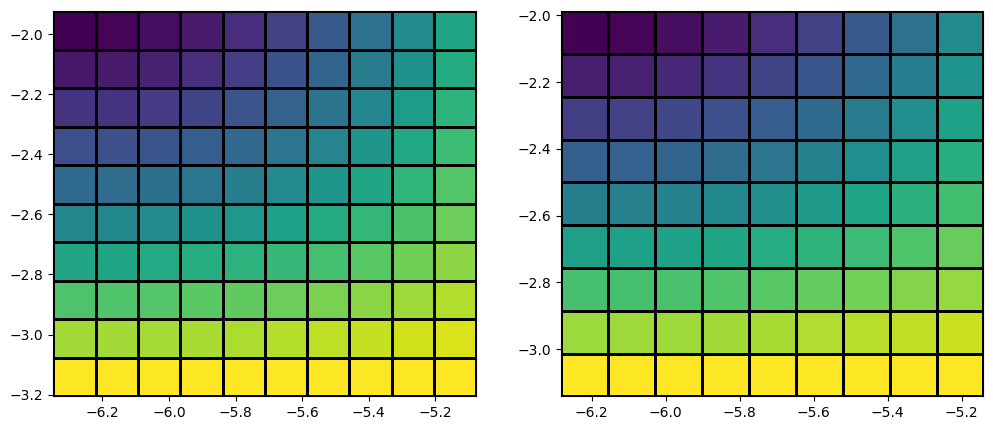

In [36]:
x_sm, y_sm, f_sm = xx[:10, :10], yy[:10, :10], f[:10, :10]

fig, ax = plt.subplots(figsize=(12,5), ncols=2)

# last row and column ignored!
# more info - https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.pcolormesh.html
ax[0].pcolormesh(x_sm, y_sm, f_sm, edgecolors='k')  
# though colormap is not plotted, it's different from previous example

# same!
ax[1].pcolormesh(x_sm, y_sm, f_sm[:-1, :-1], edgecolors='k')


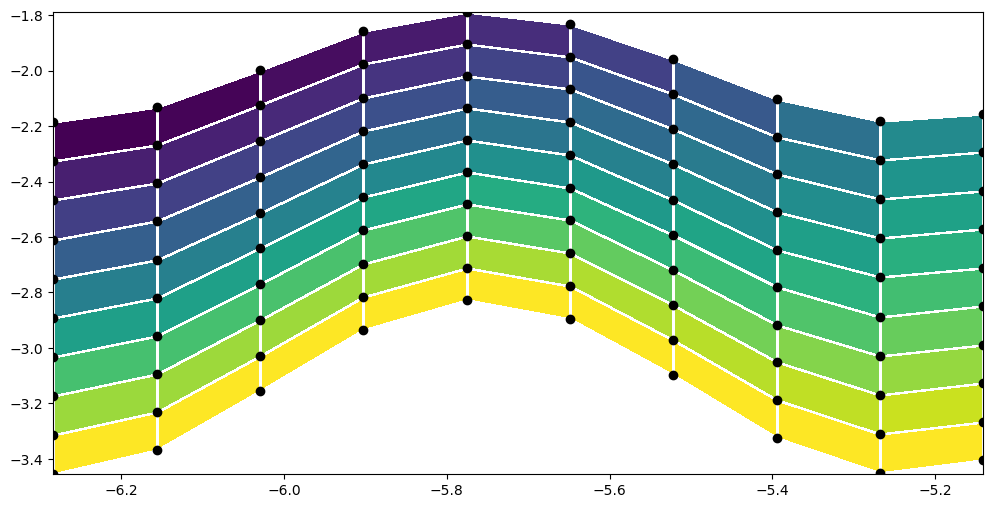

In [37]:
y_distorted = y_sm*(1 + 0.1*np.cos(6*x_sm))

plt.figure(figsize=(12,6))
plt.pcolormesh(x_sm, y_distorted, f_sm[:-1, :-1], edgecolors='w')
plt.scatter(x_sm, y_distorted, c='k')

### contour / contourf

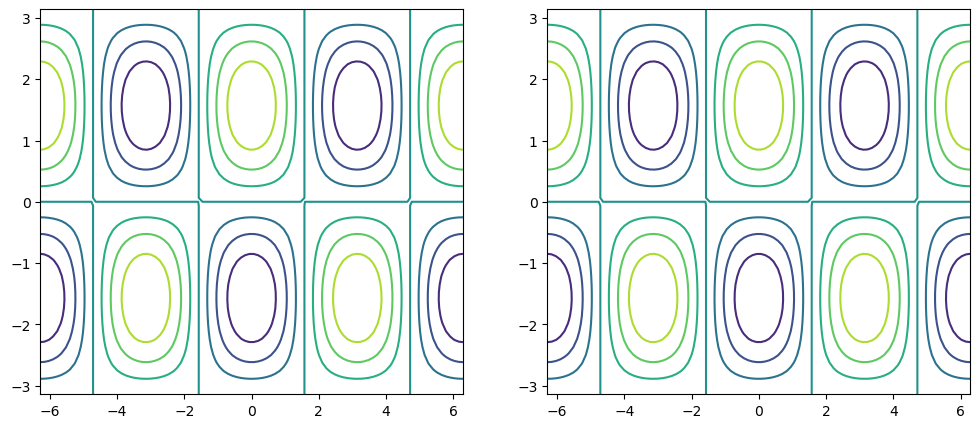

In [38]:
fig, ax = plt.subplots(figsize=(12, 5), ncols=2)

# same thing!
ax[0].contour(x1d, y1d, f)
ax[1].contour(xx, yy, f)

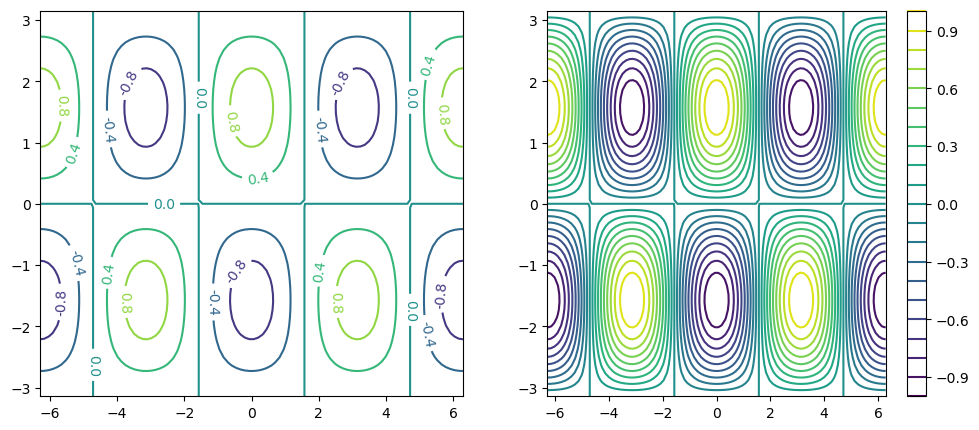

In [39]:
fig, ax = plt.subplots(figsize=(12, 5), ncols=2)

c0 = ax[0].contour(xx, yy, f, 5)  # 5 indicates the number of contour lines
c1 = ax[1].contour(xx, yy, f, 20)

plt.clabel(c0, fmt='%2.1f')
plt.colorbar(c1, ax=ax[1])

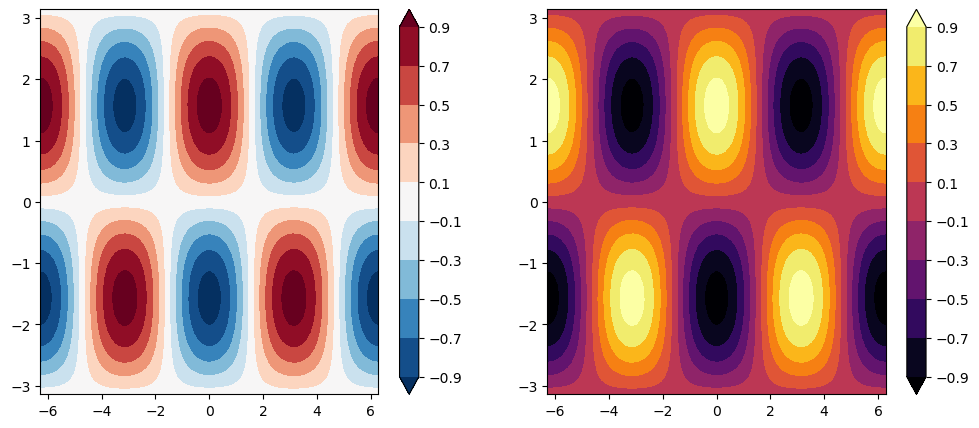

In [42]:
fig, ax = plt.subplots(figsize=(12, 5), ncols=2)

clevels = np.arange(-1, 1, 0.2) + 0.1

cf0 = ax[0].contourf(xx, yy, f, clevels, cmap='RdBu_r', extend='both')  # see what happens if we remove extend='both'
cf1 = ax[1].contourf(xx, yy, f, clevels, cmap='inferno', extend='both')

fig.colorbar(cf0, ax=ax[0])
fig.colorbar(cf1, ax=ax[1])


[More](https://matplotlib.org/stable/users/explain/colors/colormaps.html) on colormaps.

### quiver

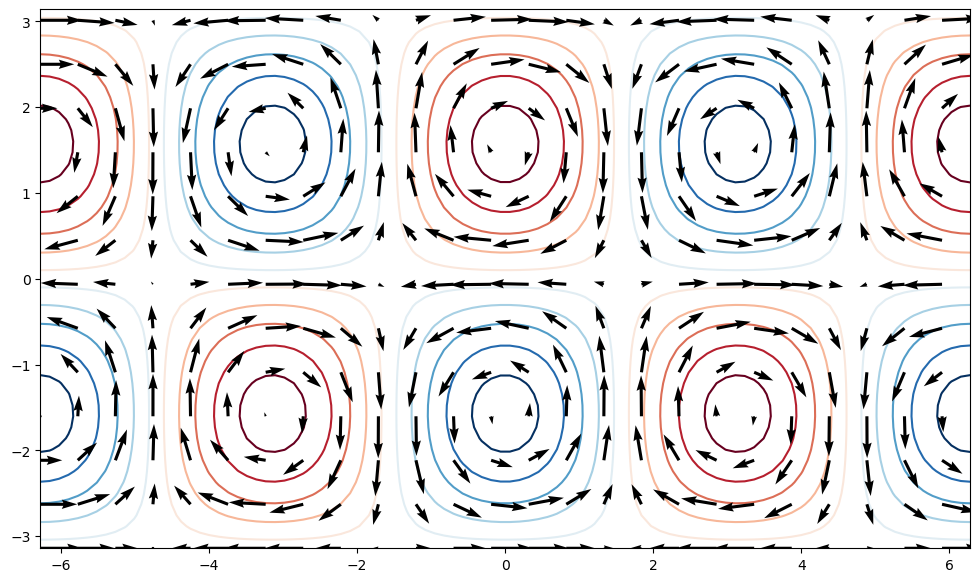

In [73]:
u = -np.cos(xx) * np.cos(yy)
v = -np.sin(xx) * np.sin(yy)

fig, ax = plt.subplots(figsize=(12, 7))
ax.contour(xx, yy, f, clevels, cmap='RdBu_r', extend='both', zorder=0)  # zorder: drawing order
ax.quiver(xx[::4, ::4], yy[::4, ::4],
           u[::4, ::4], v[::4, ::4], zorder=1)

### streamplot

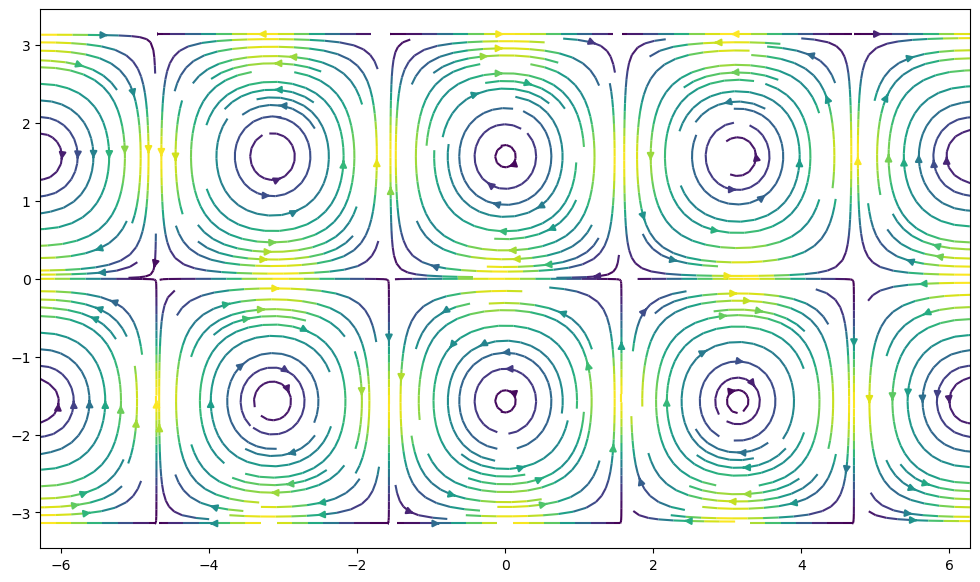

In [74]:
fig, ax = plt.subplots(figsize=(12, 7))
ax.streamplot(xx, yy, u, v, density=2, color=(u**2 + v**2))